In [5]:
import scanpy as sc

In [4]:
from pathlib import Path
import importlib.metadata as package_metadata
import warnings

import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

print("PyDESeq2:", package_metadata.version("pydeseq2"))

PyDESeq2: 0.5.4


In [61]:
import decoupler as dc

In [62]:
print("decoupler:", package_metadata.version("decoupler"))

decoupler: 2.2.0


In [63]:
! ls

CD14_Mono_JMML_vs_Control.csv		  HSC_JMML_vs_Control_merged_ann.csv
CD14_Mono_JMML_vs_Control_merged_ann.csv  base_GRN.csv
GMP_JMML_vs_Control.csv			  celloracle.ipynb
GMP_JMML_vs_Control_merged_ann.csv	  data_look_and_psbulk_DE.ipynb
HSC_JMML_vs_Control.csv			  output


In [64]:
! ls ../

celloracle-git-constraints.txt	nas	shared_group
celloracle_data			shared	storage


# Load Data

In [65]:
adata = sc.read_h5ad(f"../shared/adata_all_samples_integrated_jmml_atlas_harmony_ANNOTATED.h5ad")

/tmp/ipykernel_14593/3353920789.py:1: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = sc.read_h5ad(f"../shared/adata_all_samples_integrated_jmml_atlas_harmony_ANNOTATED.h5ad")


In [66]:
adata

AnnData object with n_obs × n_vars = 91927 × 39825
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'cell_type', 'celltype_l1_predicted', 'l1_prediction_score', 'celltype_l2_predicted', 'l2_prediction_score', 'leiden_1.5', 'leiden_0.8', 'leiden_1.2', 'batch', 'sample_groups', 'sample_celltype_l1', 'sample_celltype_l2', 'group_celltype_l1', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawrna.size', 'rawprot.size', 'n.gene', 'mt.prop', 'drop.class', 'cnts_per_cell_RNA', 'cnts_per_cell_ADT', 'log2_counts_RNA', 'log2_features_RNA', 'log2_counts_ADT', 'log2_features_ADT', 'percent_mito', 'status', 'assignment', 'lib.gen', 'class_sum', 'class', 'score_mean', 'individual', 'age', 'enrichment', 'nCount_ADT', 'nFeature_ADT', 'nCount_SCT', 'nFeature_SCT', 'integrated.sct.clus

In [67]:
adata.obs["sample_groups_wide"] = adata.obs["sample_groups"].map({ 
    "PTPN11": "JMML",
    "NF1" :"JMML",
    "NRAS":"JMML",
    "KRAS":"JMML",
    "RALD":"RALD",
    "CBL":"JMML",
    "Control": "Control",
    #"Control2": "control",
    #"Control3": "control"
})

In [68]:
adata.obs[:5]

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublet_score,predicted_doublet,S_score,G2M_score,phase,leiden_1.0,...,sex,cycle,donor,library,predicted.Stuart,predicted.score.Stuart,ident,celltype_l2_merged,leiden,celltype_l2_merged_rename
AAACCCAAGAGCAACC-1,866.0,1478.0,86.0,5.818674,0.016643,False,-0.085069,0.889050,G2M,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Late Eryth,9,Late Eryth
AAACCCAAGTAATACG-1,1367.0,2466.0,188.0,7.623682,0.130435,False,-0.223452,-0.169744,G1,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CD14 Mono,12,CD14 Mono
AAACCCACAACTTGCA-1,3361.0,8230.0,538.0,6.537060,0.045075,False,0.205761,-0.100758,S,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Early Eryth,5,Early Eryth
AAACCCACAGTGGCTC-1,1441.0,2880.0,231.0,8.020833,0.127479,False,-0.208681,-0.081074,G1,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CD14 Mono,12,CD14 Mono
AAACCCACATCCTAAG-1,560.0,780.0,67.0,8.589744,0.034065,False,-0.053019,-0.144831,G1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CD14 Mono,2,CD14 Mono


In [69]:
adata.obs['batch'].unique()

['PTPN11', 'NF1_1', 'RALD', 'NRAS_1', 'control1', ..., 'control_8', 'control_9', 'control 10', 'control 11', 'control 12']
Length: 21
Categories (21, str): ['CBL', 'KRAS', 'NF1_1', 'NF1_2', ..., 'control 11', 'control 12', 'control_8', 'control_9']

In [70]:
# Проверяем, что каждый batch принадлежит одной группе.
sample_meta = adata.obs[["batch", "sample_groups_wide"]].drop_duplicates()
assert sample_meta["batch"].notna().all(), "Есть пустые batch"
assert sample_meta["batch"].is_unique, "Один batch относится к нескольким группам"
sample_meta = sample_meta.set_index("batch")

In [71]:
sample_meta

,sample_groups_wide
batch,
PTPN11,JMML
NF1_1,JMML
RALD,RALD
NRAS_1,JMML
control1,Control
control2,Control
control3,Control
control4,Control
control5,Control


In [ ]:
# если бы не был произведен этап QC на уровне клеток - у нас был, т.к данные уже обработаны и интегрированы
# sc.pp.filter_cells(adata, min_genes=200)
# sc.pp.filter_genes(adata, min_cells=3)
# adata.shape

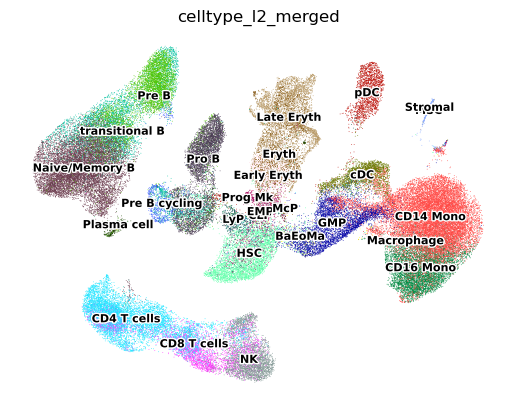

In [72]:
sc.pl.embedding(adata,
                basis = 'X_umap',
                color =  ['celltype_l2_merged'], #['celltype_l1', 'celltype_l2'],
                frameon = False,
                legend_loc = 'on data',
                legend_fontoutline = 2,
                legend_fontsize = 8
               )

# Pseudobalk object (decoupler)

In [73]:
# Сохраняем исходные баркоды перед переименованием.
if "barcode_original" not in adata.obs:
    adata.obs["barcode_original"] = adata.obs_names.to_numpy()

adata.obs_names_make_unique()

In [74]:
adata_pb = dc.pp.pseudobulk(
    adata,
    sample_col="batch",
    groups_col="celltype_l2_merged",
    layer="counts",
    mode="sum",
)

# После агрегации decoupler также сохраняет число клеток в psbulk_cells и сумму counts в psbulk_counts

In [75]:
adata_pb


AnnData object with n_obs × n_vars = 567 × 39825
    obs: 'batch', 'celltype_l2_merged', 'sample_groups', 'sample_groups_wide', 'drop.class', 'status', 'assignment', 'class', 'individual', 'age', 'pedad', 'agegroup', 'sex', 'donor', 'psbulk_cells', 'psbulk_counts'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    layers: 'psbulk_props', None (.X)

In [76]:
# hsc 24 образца у Саши 

In [78]:
adata_pb.obs

,batch,celltype_l2_merged,sample_groups,sample_groups_wide,drop.class,status,assignment,class,individual,age,pedad,agegroup,sex,donor,psbulk_cells,psbulk_counts
CBL_BaEoMa,CBL,BaEoMa,CBL,JMML,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.0,514682.0
KRAS_BaEoMa,KRAS,BaEoMa,KRAS,JMML,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,460790.0
NF1_1_BaEoMa,NF1_1,BaEoMa,NF1,JMML,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
NF1_2_BaEoMa,NF1_2,BaEoMa,NF1,JMML,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
NRAS_1_BaEoMa,NRAS_1,BaEoMa,NRAS,JMML,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,27803.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
control5_transitional B,control5,transitional B,Control,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57.0,165760.0
control6_transitional B,control6,transitional B,Control,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,110.0,308472.0
control7_transitional B,control7,transitional B,Control,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58.0,166741.0
control_8_transitional B,control_8,transitional B,Control,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.0,884874.0


In [80]:
adata_pb.obs[adata_pb.obs['celltype_l2_merged']=='HSC'].shape

(21, 16)

In [82]:
adata_pb.obs[adata_pb.obs['sample_groups_wide']=='']

CBL_BaEoMa                     JMML
KRAS_BaEoMa                    JMML
NF1_1_BaEoMa                   JMML
NF1_2_BaEoMa                   JMML
NRAS_1_BaEoMa                  JMML
                             ...   
control5_transitional B     Control
control6_transitional B     Control
control7_transitional B     Control
control_8_transitional B    Control
control_9_transitional B    Control
Name: sample_groups_wide, Length: 567, dtype: category
Categories (3, str): ['Control', 'JMML', 'RALD']

In [ ]:
adata_pb.obs[adata_pb.obs['batch']].shape


In [16]:
#old with celltype_l2_merged_rename
adata_pb

AnnData object with n_obs × n_vars = 1239 × 39825
    obs: 'batch', 'celltype_l2_merged_rename', 'celltype_l2_predicted', 'sample_groups', 'sample_celltype_l2', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'drop.class', 'status', 'assignment', 'class', 'individual', 'age', 'ann_l2', 'pedad', 'agegroup', 'sex', 'donor', 'celltype_l2_merged', 'psbulk_cells', 'psbulk_counts'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    layers: 'psbulk_props', None (.X)

In [17]:
# Явно переносим группу заболевания по идентификатору образца.
adata_pb.obs["condition"] = adata_pb.obs["batch"].map(
    sample_meta["sample_groups_wide"]
)
adata_pb

AnnData object with n_obs × n_vars = 567 × 39825
    obs: 'batch', 'celltype_l2_merged', 'sample_groups', 'sample_groups_wide', 'drop.class', 'status', 'assignment', 'class', 'individual', 'age', 'pedad', 'agegroup', 'sex', 'donor', 'psbulk_cells', 'psbulk_counts', 'condition'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    layers: 'psbulk_props', None (.X)

# DE 

In [ ]:
# CELLTYPE_LABELS = {
#     "HSC": "HSC",
#     "GMP": "GMP",
#     "CD14_Mono": "CD14 Mono",
# }


## HSC

In [50]:
CELLTYPE = "HSC"

pb = adata_pb[
    adata_pb.obs["celltype_l2_merged"].eq(CELLTYPE)
    & adata_pb.obs["condition"].isin(["JMML", "Control"])
    & adata_pb.obs["psbulk_cells"].ge(10)
    & adata_pb.obs["psbulk_counts"].ge(1000)
].copy()

meta = pb.obs[["condition"]].copy()
n = meta["condition"].value_counts().reindex(["Control", "JMML"], fill_value=0)
assert n.min() >= 2, f"Недостаточно реплик: {n.to_dict()}"

In [51]:
X = pb.X.toarray() if sparse.issparse(pb.X) else np.asarray(pb.X)
assert np.isfinite(X).all() and (X >= 0).all() and np.allclose(X, np.rint(X)), "Нужны исходные counts"
counts = pd.DataFrame(np.rint(X).astype(np.int64), index=pb.obs_names, columns=pb.var_names)
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= n.min()]
assert counts.shape[1] > 0 and counts.sum(axis=1).gt(0).all(), "После фильтрации есть пустая матрица/образец"

dds = DeseqDataSet(counts=counts, metadata=meta, design="~ condition", refit_cooks=True)
dds.deseq2()

Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.48 seconds.

Fitting dispersion trend curve...
/home/user/.local/lib/python3.14/site-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.20 seconds.

Fitting MAP dispersions...
... done in 2.20 seconds.

Fitting LFCs...
... done in 3.33 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 37 outlier genes.

Fitting dispersions...
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.04 seconds.

Fitting LFCs...
... done in 0.05 seconds.



In [52]:
ds = DeseqStats(dds, contrast=["condition", "JMML", "Control"])
ds.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: condition JMML vs Control
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG       40.166432       -0.148573  0.311552 -0.476882  0.633446  0.736833
A2M         8.584016        2.844768  0.669709  4.247767  0.000022  0.000557
A2M-AS1     7.043198        0.637393  0.522357  1.220225  0.222380  0.350674
A2ML1-AS1   7.821088        1.110828  0.659633  1.684009  0.092180  0.192484
AAAS       18.960431       -0.680119  0.274509 -2.477585  0.013227  0.052125
...              ...             ...       ...       ...       ...       ...
ZWINT      40.992865       -1.765992  0.555007 -3.181930  0.001463  0.011192
ZXDC       54.296958        0.666613  0.499171  1.335441  0.181732  0.304681
ZYG11B     21.894804        0.854455  0.390476  2.188238  0.028652  0.088198
ZYX        60.042965       -0.531259  0.331219 -1.603949  0.108725  0.215743
ZZEF1      47.148598        0.666593  0.423390  1.574418  0.115391  0.224320

[11491 rows

... done in 2.91 seconds.



In [53]:
res = ds.results_df.sort_values("padj")
res.to_csv(f"{CELLTYPE.replace(' ', '_')}_JMML_vs_Control_merged_ann.csv")
res

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
HYI,33.778782,-2.075777,0.238600,-8.699825,3.323956e-18,3.174221e-14
MTSS1,29.153396,3.072049,0.355480,8.641980,5.524708e-18,3.174221e-14
AKR7A2,90.307744,-1.489312,0.180816,-8.236614,1.771524e-16,6.785526e-13
CALCOCO2,133.397010,1.373446,0.170681,8.046878,8.493250e-16,2.439898e-12
STUB1,68.775365,-1.394787,0.178191,-7.827468,4.977918e-15,1.144025e-11
...,...,...,...,...,...,...
ANGEL1,8.687189,-0.000638,0.362530,-0.001760,9.985956e-01,9.989433e-01
COPS9,102.967291,0.001099,0.740664,0.001483,9.988164e-01,9.990033e-01
AL391069.2,14.947844,0.000944,0.643213,0.001467,9.988294e-01,9.990033e-01
TMEM189,19.882299,0.000048,0.302593,0.000158,9.998739e-01,9.999236e-01


In [7]:
res_1 = pd.read_csv('HSC_JMML_vs_Control_merged_ann.csv', index_col=0)
res_1

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
HYI,33.778782,-2.075777,0.238600,-8.699825,3.323956e-18,3.174221e-14
MTSS1,29.153396,3.072049,0.355480,8.641980,5.524708e-18,3.174221e-14
AKR7A2,90.307744,-1.489312,0.180816,-8.236614,1.771524e-16,6.785526e-13
CALCOCO2,133.397010,1.373446,0.170681,8.046878,8.493250e-16,2.439898e-12
STUB1,68.775365,-1.394787,0.178191,-7.827468,4.977918e-15,1.144025e-11
...,...,...,...,...,...,...
ANGEL1,8.687189,-0.000638,0.362530,-0.001760,9.985956e-01,9.989433e-01
COPS9,102.967291,0.001099,0.740664,0.001483,9.988164e-01,9.990033e-01
AL391069.2,14.947844,0.000944,0.643213,0.001467,9.988294e-01,9.990033e-01
TMEM189,19.882299,0.000048,0.302593,0.000158,9.998739e-01,9.999236e-01


In [54]:
res[res.index.str.contains('ZE')]


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ZEB2,457.591747,1.383986,0.322499,4.291445,0.000018,0.000483
ZER1,27.089586,1.308458,0.358626,3.648535,0.000264,0.003219
ZEB1,218.042411,1.164830,0.575001,2.025785,0.042787,0.114101
ZZEF1,47.148598,0.666593,0.423390,1.574418,0.115391,0.224320
ZEB1-AS1,13.392119,-0.288887,0.386807,-0.746849,0.455154,0.585097


In [8]:
DEGs_HSC_df = res_1.query("padj < 0.05 and abs(log2FoldChange) >= 1")
DEGs_HSC_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
HYI,33.778782,-2.075777,0.238600,-8.699825,3.323956e-18,3.174221e-14
MTSS1,29.153396,3.072049,0.355480,8.641980,5.524708e-18,3.174221e-14
AKR7A2,90.307744,-1.489312,0.180816,-8.236614,1.771524e-16,6.785526e-13
CALCOCO2,133.397010,1.373446,0.170681,8.046878,8.493250e-16,2.439898e-12
STUB1,68.775365,-1.394787,0.178191,-7.827468,4.977918e-15,1.144025e-11
...,...,...,...,...,...,...
TCF19,12.655321,-1.115011,0.445534,-2.502641,1.232707e-02,4.952808e-02
MTMR10,44.921274,1.312858,0.524785,2.501706,1.235964e-02,4.962426e-02
PARG,41.791051,1.132898,0.452850,2.501710,1.235951e-02,4.962426e-02
SMIM10,18.366141,-1.396014,0.558397,-2.500040,1.241792e-02,4.978865e-02


In [25]:
[x for x in DEGs_HSC_df.index if 'AC016' in x]

['AC016735.1', 'AC016168.2']

In [27]:
[x for x in DEGs_HSC_df.index if 'ZE' in x]


['ZEB2', 'ZER1']

## GMP

In [44]:
CELLTYPE = "GMP"

pb = adata_pb[
    adata_pb.obs["celltype_l2_merged"].eq(CELLTYPE)
    & adata_pb.obs["condition"].isin(["JMML", "Control"])
    & adata_pb.obs["psbulk_cells"].ge(10)
    & adata_pb.obs["psbulk_counts"].ge(1000)
].copy()

meta = pb.obs[["condition"]].copy()
n = meta["condition"].value_counts().reindex(["Control", "JMML"], fill_value=0)
assert n.min() >= 2, f"Недостаточно реплик: {n.to_dict()}"

In [45]:
X = pb.X.toarray() if sparse.issparse(pb.X) else np.asarray(pb.X)
assert np.isfinite(X).all() and (X >= 0).all() and np.allclose(X, np.rint(X)), "Нужны исходные counts"
counts = pd.DataFrame(np.rint(X).astype(np.int64), index=pb.obs_names, columns=pb.var_names)
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= n.min()]
assert counts.shape[1] > 0 and counts.sum(axis=1).gt(0).all(), "После фильтрации есть пустая матрица/образец"

dds = DeseqDataSet(counts=counts, metadata=meta, design="~ condition", refit_cooks=True)
dds.deseq2()

Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.38 seconds.

Fitting dispersion trend curve...
... done in 0.18 seconds.

Fitting MAP dispersions...
... done in 2.42 seconds.

Fitting LFCs...
... done in 2.44 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 16 outlier genes.

Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.



In [46]:
ds = DeseqStats(dds, contrast=["condition", "JMML", "Control"])
ds.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: condition JMML vs Control
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG     30.937086       -1.443529  0.458536 -3.148126  0.001643  0.016600
AAAS     14.646932       -0.431692  0.326448 -1.322391  0.186038  0.321235
AAGAB    36.096696        0.370352  0.340276  1.088388  0.276424  0.420077
AAK1    167.026341        0.785111  0.300364  2.613865  0.008952  0.043894
AAMDC    29.980513       -1.162540  0.356330 -3.262537  0.001104  0.013769
...            ...             ...       ...       ...       ...       ...
ZWINT    62.256702       -1.180930  0.487114 -2.424341  0.015336  0.061229
ZXDC     68.588094        1.111152  0.651208  1.706293  0.087954  0.191710
ZYG11B   33.440497        0.704743  0.447898  1.573445  0.115616  0.230309
ZYX     100.840096       -0.640156  0.248260 -2.578567  0.009921  0.046780
ZZEF1    68.792181        1.185099  0.456393  2.596663  0.009413  0.045297

[9404 rows x 6 columns]


... done in 2.91 seconds.



In [47]:
res = ds.results_df.sort_values("padj")
res.to_csv(f"{CELLTYPE.replace(' ', '_')}_JMML_vs_Control_merged_ann.csv")
res

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
PPDPF,305.327185,-2.351002,0.317591,-7.402608,1.335359e-13,1.133987e-09
GPAT3,45.711202,4.255962,0.650423,6.543378,6.014464e-11,2.553741e-07
SLC26A3,38.731626,4.941445,0.773001,6.392542,1.631502e-10,4.618238e-07
ARF5,57.684010,-3.013062,0.482241,-6.248035,4.156484e-10,8.824216e-07
TRAPPC1,180.565297,-1.959124,0.326068,-6.008331,1.874431e-09,2.999757e-06
...,...,...,...,...,...,...
ZNRF3,9.966416,0.207100,0.566830,0.365366,7.148385e-01,NaN
ZSCAN12,4.104749,0.338342,0.724963,0.466703,6.407124e-01,NaN
ZSCAN29,7.773796,-0.067419,0.523502,-0.128784,8.975282e-01,NaN
ZSWIM4,8.280651,0.967030,0.555639,1.740394,8.178980e-02,NaN


In [11]:
res_3 = pd.read_csv('GMP_JMML_vs_Control_merged_ann.csv', index_col=0)
res_3

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
PPDPF,305.327185,-2.351002,0.317591,-7.402608,1.335359e-13,1.133987e-09
GPAT3,45.711202,4.255962,0.650423,6.543378,6.014464e-11,2.553741e-07
SLC26A3,38.731626,4.941445,0.773001,6.392542,1.631502e-10,4.618238e-07
ARF5,57.684010,-3.013062,0.482241,-6.248035,4.156484e-10,8.824216e-07
TRAPPC1,180.565297,-1.959124,0.326068,-6.008331,1.874431e-09,2.999757e-06
...,...,...,...,...,...,...
ZNRF3,9.966416,0.207100,0.566830,0.365366,7.148385e-01,NaN
ZSCAN12,4.104749,0.338342,0.724963,0.466703,6.407124e-01,NaN
ZSCAN29,7.773796,-0.067419,0.523502,-0.128784,8.975282e-01,NaN
ZSWIM4,8.280651,0.967030,0.555639,1.740394,8.178980e-02,NaN


In [48]:
res[res.index.str.contains('ZE')]


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ZEB2,1277.934604,1.402713,0.427250,3.283120,0.001027,0.013110
ZZEF1,68.792181,1.185099,0.456393,2.596663,0.009413,0.045297
ZEB1,51.937028,1.608951,0.773389,2.080390,0.037490,0.107926
ZEB2-AS1,15.705376,-0.021215,0.441572,-0.048044,0.961681,0.977451
ZER1,10.183165,0.422240,0.609412,0.692865,0.488394,NaN


In [13]:
DEGs_GMP_df = res_3.query("padj < 0.05 and abs(log2FoldChange) >= 1")
DEGs_GMP_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
PPDPF,305.327185,-2.351002,0.317591,-7.402608,1.335359e-13,1.133987e-09
GPAT3,45.711202,4.255962,0.650423,6.543378,6.014464e-11,2.553741e-07
SLC26A3,38.731626,4.941445,0.773001,6.392542,1.631502e-10,4.618238e-07
ARF5,57.684010,-3.013062,0.482241,-6.248035,4.156484e-10,8.824216e-07
TRAPPC1,180.565297,-1.959124,0.326068,-6.008331,1.874431e-09,2.999757e-06
...,...,...,...,...,...,...
RBL1,104.546742,1.401762,0.550095,2.548220,1.082741e-02,4.930101e-02
ABTB2,20.159336,2.131405,0.836669,2.547488,1.085016e-02,4.937811e-02
FCHSD2,320.927954,1.778723,0.699153,2.544114,1.095555e-02,4.975107e-02
TMEM141,37.708234,-1.047560,0.412039,-2.542383,1.100994e-02,4.994465e-02


In [33]:
[x for x in DEGs_GMP_df.index if 'ZE' in x]

['ZEB2', 'ZZEF1']

In [34]:
[x for x in DEGs_GMP_df.index if 'AC01' in x]


['AC015871.1']

## CD14 Mono

In [35]:
CELLTYPE = "CD14 Mono"

pb = adata_pb[
    adata_pb.obs["celltype_l2_merged"].eq(CELLTYPE)
    & adata_pb.obs["condition"].isin(["JMML", "Control"])
    & adata_pb.obs["psbulk_cells"].ge(10)
    & adata_pb.obs["psbulk_counts"].ge(1000)
].copy()

meta = pb.obs[["condition"]].copy()
n = meta["condition"].value_counts().reindex(["Control", "JMML"], fill_value=0)
assert n.min() >= 2, f"Недостаточно реплик: {n.to_dict()}"

In [36]:
X = pb.X.toarray() if sparse.issparse(pb.X) else np.asarray(pb.X)
assert np.isfinite(X).all() and (X >= 0).all() and np.allclose(X, np.rint(X)), "Нужны исходные counts"
counts = pd.DataFrame(np.rint(X).astype(np.int64), index=pb.obs_names, columns=pb.var_names)
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= n.min()]
assert counts.shape[1] > 0 and counts.sum(axis=1).gt(0).all(), "После фильтрации есть пустая матрица/образец"

dds = DeseqDataSet(counts=counts, metadata=meta, design="~ condition", refit_cooks=True)
dds.deseq2()

Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.05 seconds.

Fitting dispersion trend curve...
... done in 0.24 seconds.

Fitting MAP dispersions...
... done in 2.30 seconds.

Fitting LFCs...
... done in 2.62 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 87 outlier genes.

Fitting dispersions...
... done in 0.07 seconds.

Fitting MAP dispersions...
... done in 0.07 seconds.

Fitting LFCs...
... done in 0.08 seconds.



In [37]:
ds = DeseqStats(dds, contrast=["condition", "JMML", "Control"])
ds.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: condition JMML vs Control
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG       70.867598       -1.182555  0.284431 -4.157616  0.000032  0.000767
A1BG-AS1    6.982620       -0.283185  0.471075 -0.601147  0.547742  0.663117
AAAS       14.907298       -0.800325  0.309554 -2.585414  0.009726  0.038347
AACS        7.496983        0.107144  0.269373  0.397752  0.690813  0.780981
AAGAB      60.783188        1.186556  0.282404  4.201620  0.000027  0.000671
...              ...             ...       ...       ...       ...       ...
ZXDB        2.271661        0.065211  0.628524  0.103752  0.917366  0.945868
ZXDC       87.770233        0.645611  0.502259  1.285414  0.198648  0.318775
ZYG11B     60.099559       -0.102554  0.355250 -0.288682  0.772825  0.845311
ZYX       234.479692       -0.653616  0.164317 -3.977763  0.000070  0.001328
ZZEF1     108.652615        0.853416  0.386113  2.210277  0.027086  0.077146

[11615 rows

... done in 2.78 seconds.



In [38]:
res = ds.results_df.sort_values("padj")
res.to_csv(f"{CELLTYPE.replace(' ', '_')}_JMML_vs_Control_merged_ann.csv")
res

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
SLC26A3,46.904482,5.018376,0.691832,7.253751,4.053848e-13,2.051247e-09
FAAP20,124.706068,-1.998798,0.275466,-7.256051,3.985549e-13,2.051247e-09
DRAM1,106.752173,2.117324,0.293363,7.217426,5.298099e-13,2.051247e-09
GPAA1,50.276962,-1.815672,0.253471,-7.163247,7.878808e-13,2.287809e-09
PPDPF,416.266011,-2.067189,0.292296,-7.072254,1.524374e-12,3.541122e-09
...,...,...,...,...,...,...
KLF11,56.524765,-0.000662,0.295428,-0.002240,9.982128e-01,9.985567e-01
RFX5,16.255395,-0.000586,0.285432,-0.002055,9.983606e-01,9.986186e-01
GNPDA2,6.738162,-0.000355,0.377477,-0.000939,9.992506e-01,9.994227e-01
TTC3,126.596011,0.000080,0.208565,0.000384,9.996935e-01,9.996935e-01


In [10]:
res_2 = pd.read_csv('CD14_Mono_JMML_vs_Control_merged_ann.csv', index_col=0)
res_2

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
SLC26A3,46.904482,5.018376,0.691832,7.253751,4.053848e-13,2.051247e-09
FAAP20,124.706068,-1.998798,0.275466,-7.256051,3.985549e-13,2.051247e-09
DRAM1,106.752173,2.117324,0.293363,7.217426,5.298099e-13,2.051247e-09
GPAA1,50.276962,-1.815672,0.253471,-7.163247,7.878808e-13,2.287809e-09
PPDPF,416.266011,-2.067189,0.292296,-7.072254,1.524374e-12,3.541122e-09
...,...,...,...,...,...,...
KLF11,56.524765,-0.000662,0.295428,-0.002240,9.982128e-01,9.985567e-01
RFX5,16.255395,-0.000586,0.285432,-0.002055,9.983606e-01,9.986186e-01
GNPDA2,6.738162,-0.000355,0.377477,-0.000939,9.992506e-01,9.994227e-01
TTC3,126.596011,0.000080,0.208565,0.000384,9.996935e-01,9.996935e-01


In [43]:
res[res.index.str.contains('ZE')]

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ZEB2,2738.003128,1.528138,0.425730,3.589455,0.000331,0.003777
ZEB1,13.077883,1.932593,0.606991,3.183891,0.001453,0.010405
ZZEF1,108.652615,0.853416,0.386113,2.210277,0.027086,0.077146
ZER1,24.541501,0.790371,0.450965,1.752622,0.079667,0.164620
ZEB2-AS1,30.301993,-0.424971,0.360577,-1.178585,0.238564,0.363066


In [12]:
DEGs_CD14_Mono_df = res_2.query("padj < 0.05 and abs(log2FoldChange) >= 1")
DEGs_CD14_Mono_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
SLC26A3,46.904482,5.018376,0.691832,7.253751,4.053848e-13,2.051247e-09
FAAP20,124.706068,-1.998798,0.275466,-7.256051,3.985549e-13,2.051247e-09
DRAM1,106.752173,2.117324,0.293363,7.217426,5.298099e-13,2.051247e-09
GPAA1,50.276962,-1.815672,0.253471,-7.163247,7.878808e-13,2.287809e-09
PPDPF,416.266011,-2.067189,0.292296,-7.072254,1.524374e-12,3.541122e-09
...,...,...,...,...,...,...
LINC01138,33.951714,1.322536,0.538470,2.456098,1.404547e-02,4.919725e-02
ATRN,67.587580,1.286187,0.523891,2.455066,1.408586e-02,4.927931e-02
FARS2,86.406243,1.204938,0.490864,2.454727,1.409915e-02,4.930723e-02
SMC5,142.196521,1.032747,0.420889,2.453726,1.413848e-02,4.938901e-02


In [40]:
[x for x in DEGs_CD14_Mono_df.index if 'ZE' in x]

['ZEB2', 'ZEB1']

In [41]:
[x for x in DEGs_CD14_Mono_df.index if 'AC016' in x]

[]

## Save DEGs 

In [16]:
DEGs_HSC_df.to_csv('HSC_DEGs_Masha.csv')

In [14]:
DEGs_CD14_Mono_df.to_csv('CD14_Mono_DEGs_Masha.csv')

In [15]:
DEGs_GMP_df.to_csv('GMP_DEGs_Masha.csv')

# OLD DE probe

In [13]:
# CELLTYPE_COL = "celltype_l2_merged_rename"
# SAMPLE_COL = "batch"
# COUNTS_SOURCE = "counts" # adata.layers["counts"]

# CELLTYPE_LABELS = {
#     "HSC": "HSC",
#     "GMP": "GMP",
#     "CD14_Mono": "CD14 Mono",
# }

# MIN_CELLS = 20
# MIN_TOTAL_COUNTS = 1000

# # MIN_REPLICATES = 2

# MIN_GENE_COUNT = 10
# FDR = 0.05
# LFC_CUTOFF = 1.0
# N_CPUS = 4

# OUTDIR = Path("output/pseudobulk_JMML_vs_Control")
# OUTDIR.mkdir(parents=True, exist_ok=True)

# required_columns = [CELLTYPE_COL, SAMPLE_COL, "sample_groups"]
# missing_columns = [c for c in required_columns if c not in adata.obs.columns]

# if missing_columns:
#     raise KeyError(f"В adata.obs отсутствуют колонки: {missing_columns}")

# print("Размер adata:", adata.shape)
# print("Доступные layers:", list(adata.layers.keys()))

# print("\nКлеточные типы:")
# display(adata.obs[CELLTYPE_COL].value_counts(dropna=False))

# print("\nИсходные группы:")
# display(adata.obs["sample_groups"].value_counts(dropna=False))

# print(f"\nПервые значения {SAMPLE_COL}:")
# display(adata.obs[[SAMPLE_COL, "sample_groups", CELLTYPE_COL]].head(10))

In [14]:
# group_mapping = {
#     "PTPN11": "JMML",
#     "NF1": "JMML",
#     "NRAS": "JMML",
#     "KRAS": "JMML",
#     "RALD": "RALD",
#     "CBL": "JMML",
#     "Control": "Control",
# }

# adata.obs["sample_groups_wide"] = (
#     adata.obs["sample_groups"].map(group_mapping)
# )

# # print("Соответствие исходных и объединённых групп:")
# # display(
# #     pd.crosstab(
# #         adata.obs["sample_groups"],
# #         adata.obs["sample_groups_wide"],
# #         dropna=False,
# #     )
# # )

# unmapped = adata.obs.loc[
#     adata.obs["sample_groups"].notna()
#     & adata.obs["sample_groups_wide"].isna(),
#     "sample_groups",
# ].unique()

# if len(unmapped):
#     warnings.warn(
#         f"Эти группы не включены в mapping и будут исключены: {list(unmapped)}"
#     )

# selected_mask = (
#     adata.obs[CELLTYPE_COL].isin(CELLTYPE_LABELS.values())
#     & adata.obs["sample_groups_wide"].isin(["Control", "JMML"])
# )

# cell_indices = np.flatnonzero(selected_mask.to_numpy())
# obs_selected = adata.obs.iloc[cell_indices].copy()

# if obs_selected.empty:
#     raise ValueError(
#         "Нет подходящих клеток. Проверьте названия типов и групп."
#     )

# bad_sample_ids = (
#     obs_selected[SAMPLE_COL].isna()
#     | obs_selected[SAMPLE_COL].astype(str).str.strip().eq("")
# )

# if bad_sample_ids.any():
#     raise ValueError(
#         f"У {int(bad_sample_ids.sum())} выбранных клеток отсутствует "
#         f"идентификатор в {SAMPLE_COL!r}. "
#         "Укажите заполненную колонку независимых биологических образцов."
#     )

# obs_selected[SAMPLE_COL] = (
#     obs_selected[SAMPLE_COL].astype(str).str.strip()
# )
# obs_selected["condition"] = (
#     obs_selected["sample_groups_wide"].astype(str)
# )

# # Один идентификатор образца не должен принадлежать двум группам.
# conditions_per_sample = (
#     obs_selected.groupby(SAMPLE_COL, observed=True)["condition"].nunique()
# )

# conflicting_samples = conditions_per_sample[
#     conditions_per_sample > 1
# ].index.tolist()

# if conflicting_samples:
#     raise ValueError(
#         "Один sample ID относится к нескольким группам: "
#         f"{conflicting_samples}. Проверьте SAMPLE_COL."
#     )

# missing_celltypes = (
#     set(CELLTYPE_LABELS.values())
#     - set(obs_selected[CELLTYPE_COL].dropna())
# )

# if missing_celltypes:
#     warnings.warn(
#         f"Среди выбранных клеток отсутствуют типы: {sorted(missing_celltypes)}"
#     )

# # print("Число клеток по типам и группам:")
# # display(
# #     pd.crosstab(
# #         obs_selected[CELLTYPE_COL],
# #         obs_selected["condition"],
# #     )
# # )

# # print("Число клеток по образцам и типам:")
# # display(
# #     pd.crosstab(
# #         [obs_selected[SAMPLE_COL], obs_selected["condition"]],
# #         obs_selected[CELLTYPE_COL],
# #     )
# # )

In [15]:
# if COUNTS_SOURCE == "X":
#     count_matrix = adata.X
#     gene_names = pd.Index(adata.var_names.astype(str), name="gene")

# elif COUNTS_SOURCE == "raw":
#     if adata.raw is None:
#         raise ValueError("adata.raw отсутствует.")
#     count_matrix = adata.raw.X
#     gene_names = pd.Index(adata.raw.var_names.astype(str), name="gene")

# else:
#     if COUNTS_SOURCE not in adata.layers:
#         raise KeyError(
#             f"Layer {COUNTS_SOURCE!r} отсутствует. "
#             f"Доступны: {list(adata.layers.keys())}"
#         )
#     count_matrix = adata.layers[COUNTS_SOURCE]
#     gene_names = pd.Index(adata.var_names.astype(str), name="gene")

# if not gene_names.is_unique:
#     raise ValueError(
#         "Идентификаторы генов не уникальны. "
#         "Используйте уникальные gene IDs; не объединяйте гены "
#         "по повторяющимся символам без отдельной проверки."
#     )

# # Берём только выбранные клетки.
# X = count_matrix[cell_indices, :]

# if sparse.issparse(X):
#     X = X.tocsr(copy=True)
#     X.sum_duplicates()
#     values = X.data
# else:
#     X = np.asarray(X)
#     values = X.ravel()

# if not np.isfinite(values).all():
#     raise ValueError("В матрице counts есть NaN или Inf.")

# if (values < 0).any():
#     raise ValueError("В матрице есть отрицательные значения.")

# if not np.allclose(values, np.rint(values), rtol=0, atol=1e-6):
#     raise ValueError(
#         "Матрица содержит нецелочисленные значения. "
#         "Нужны исходные counts, а не нормализованная экспрессия."
#     )

# if sparse.issparse(X):
#     X.data = np.rint(X.data).astype(np.int64)
#     X = X.astype(np.int64)
# else:
#     X = sparse.csr_matrix(np.rint(X).astype(np.int64))

# print("Выбранная матрица:", X.shape)
# print("Суммарные counts:", int(X.sum()))

In [16]:
# pseudobulk = {}
# qc_tables = []

# for celltype_key, celltype_label in CELLTYPE_LABELS.items():
#     positions = np.flatnonzero(
#         obs_selected[CELLTYPE_COL].eq(celltype_label).to_numpy()
#     )

#     if len(positions) == 0:
#         continue

#     obs_ct = obs_selected.iloc[positions].copy()
#     X_ct = X[positions, :]

#     # Каждая строка aggregation_matrix соответствует одному образцу.
#     sample_codes, sample_ids = pd.factorize(
#         obs_ct[SAMPLE_COL],
#         sort=True,
#     )
#     sample_ids = pd.Index(sample_ids, name=SAMPLE_COL)

#     aggregation_matrix = sparse.csr_matrix(
#         (
#             np.ones(len(sample_codes), dtype=np.int64),
#             (sample_codes, np.arange(len(sample_codes))),
#         ),
#         shape=(len(sample_ids), len(sample_codes)),
#     )

#     summed_counts = aggregation_matrix @ X_ct

#     counts_df = pd.DataFrame(
#         summed_counts.toarray(),
#         index=sample_ids,
#         columns=gene_names,
#     )

#     metadata = (
#         obs_ct.groupby(SAMPLE_COL, observed=True)
#         .agg(
#             condition=("condition", "first"),
#             n_cells=("condition", "size"),
#         )
#         .reindex(sample_ids)
#     )

#     metadata["total_counts"] = counts_df.sum(axis=1)
#     metadata["celltype"] = celltype_label

#     metadata["pass_qc"] = (
#         metadata["n_cells"].ge(MIN_CELLS)
#         & metadata["total_counts"].ge(MIN_TOTAL_COUNTS)
#     )

#     qc_tables.append(metadata.reset_index())

#     retained_ids = metadata.index[metadata["pass_qc"]]

#     pseudobulk[celltype_key] = {
#         "counts": counts_df.loc[retained_ids].copy(),
#         "metadata": metadata.loc[retained_ids].copy(),
#     }

# qc_all = pd.concat(qc_tables, ignore_index=True)
# qc_all.to_csv(OUTDIR / "pseudobulk_QC.csv", index=False)

# print("QC всех pseudobulk-профилей:")
# display(qc_all)

# print("Число образцов после QC:")
# display(
#     pd.crosstab(
#         qc_all.loc[qc_all["pass_qc"], "celltype"],
#         qc_all.loc[qc_all["pass_qc"], "condition"],
#     ).reindex(columns=["Control", "JMML"], fill_value=0)
# )

In [19]:
# de_results = {}
# for ct, pb in pseudobulk.items():
#     counts, meta = pb["counts"], pb["metadata"]
#     assert meta["condition"].value_counts().reindex(["Control", "JMML"], fill_value=0).min() >= 2, f"{ct}: недостаточно реплик"
#     counts = counts.loc[:, (counts >= 10).sum() >= meta["condition"].value_counts().min()]
#     dds = DeseqDataSet(counts=counts, metadata=meta, design="~ condition", refit_cooks=True)
#     dds.deseq2()
#     ds = DeseqStats(dds, contrast=["condition", "JMML", "Control"])
#     ds.summary()
#     de_results[ct] = ds.results_df.sort_values("padj")
#     de_results[ct].to_csv(f"{ct}_JMML_vs_Control.csv")

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 2.21 seconds.

Fitting dispersion trend curve...
... done in 0.27 seconds.

Fitting MAP dispersions...
... done in 2.23 seconds.

Fitting LFCs...
... done in 3.10 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 219 outlier genes.

Fitting dispersions...
... done in 0.12 seconds.

Fitting MAP dispersions...
... done in 0.09 seconds.

Fitting LFCs...
... done in 0.10 seconds.

Running Wald tests...
... done in 2.93 seconds.



Log2 fold change & Wald test p-value: condition JMML vs Control
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
gene                                                                        
A1BG       37.360220        0.990329  0.872498  1.135050  0.256354  0.890574
A1BG-AS1    6.013816        0.352676  1.495633  0.235804  0.813585  0.977052
A2M        16.579027        1.944055  1.597103  1.217238  0.223514  0.878510
A2M-AS1     7.230598        0.633502  1.531670  0.413602  0.679166  0.947500
A2ML1-AS1  11.773002        1.438739  1.531400  0.939492  0.347478  0.904804
...              ...             ...       ...       ...       ...       ...
ZXDB        2.855683        0.876364  2.489930  0.351963  0.724866       NaN
ZXDC       70.547178        0.119539  0.570552  0.209514  0.834047  0.981496
ZYG11B     26.832777        1.121637  1.055907  1.062250  0.288122  0.901808
ZYX        47.803854        0.483694  0.686753  0.704319  0.481234  0.909412
ZZEF1      6

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 2.27 seconds.

Fitting dispersion trend curve...
... done in 0.22 seconds.

Fitting MAP dispersions...
... done in 2.09 seconds.

Fitting LFCs...
... done in 2.71 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 42 outlier genes.

Fitting dispersions...
... done in 0.04 seconds.

Fitting MAP dispersions...
... done in 0.04 seconds.

Fitting LFCs...
... done in 0.05 seconds.

Running Wald tests...
... done in 2.72 seconds.



Log2 fold change & Wald test p-value: condition JMML vs Control
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
gene                                                                      
A1BG     20.320964       -1.723227  0.672637 -2.561897  0.010410  0.029914
AAAS     12.359796       -1.088747  0.539515 -2.018010  0.043590  0.086697
AACS      7.365172       -0.753102  0.772241 -0.975216  0.329453       NaN
AAGAB    28.851980        0.540818  0.470508  1.149435  0.250377  0.349490
AAK1    126.999443        1.167970  0.368012  3.173725  0.001505  0.006738
...            ...             ...       ...       ...       ...       ...
ZWINT    48.343098       -1.863435  0.558466 -3.336700  0.000848  0.004362
ZXDC     49.277531        4.252988  0.951195  4.471206  0.000008  0.000103
ZYG11B   25.912081        0.509030  0.648107  0.785410  0.432213  0.535591
ZYX      71.086571       -0.881109  0.341331 -2.581389  0.009840  0.028756
ZZEF1    54.462075        2.046731  

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 2.14 seconds.

Fitting dispersion trend curve...
/home/user/.local/lib/python3.14/site-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.16 seconds.

Fitting MAP dispersions...
... done in 2.18 seconds.

Fitting LFCs...
... done in 2.50 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 38 outlier genes.

Fitting dispersions...
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.04 seconds.

Fitting LFCs...
... done in 0.05 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition JMML vs Control
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
gene                                                                      
A1BG     53.694065       -1.201985  0.329379 -3.649243  0.000263  0.001597
AAAS     12.273796       -1.107128  0.330066 -3.354265  0.000796  0.003747
AAGAB    48.723632        1.542779  0.326021  4.732138  0.000002  0.000043
AAK1    175.564704        0.842936  0.245415  3.434738  0.000593  0.003000
AAMDC    20.895248       -0.386485  0.279704 -1.381762  0.167045  0.247763
...            ...             ...       ...       ...       ...       ...
ZWINT     8.649605       -1.476946  0.519617 -2.842376  0.004478  0.014162
ZXDC     64.419764        1.111869  0.544704  2.041234  0.041228  0.080688
ZYG11B   49.798258       -0.294363  0.397303 -0.740903  0.458752  0.552679
ZYX     183.346542       -0.723254  0.184959 -3.910356  0.000092  0.000740
ZZEF1    86.339920        1.020143  

... done in 2.73 seconds.



In [20]:
# DEGs_CD14_df = de_results["CD14_Mono"].query("padj < 0.05 and abs(log2FoldChange) >= 1")
# DEGs_CD14_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
IGF2BP3,82.270885,4.279195,0.506853,8.442674,3.101582e-17,2.973177e-13
FKBP2,68.231232,-5.020387,0.632105,-7.942328,1.984209e-15,9.510315e-12
TBK1,107.497337,2.085792,0.267245,7.804790,5.960087e-15,1.904447e-11
RUVBL2,22.242922,-1.708521,0.227681,-7.504013,6.189328e-14,1.483272e-10
MRPL53,23.228365,-3.973669,0.533602,-7.446877,9.557590e-14,1.526984e-10
...,...,...,...,...,...,...
SEC31B,11.804446,1.047322,0.458465,2.284407,2.234765e-02,4.966950e-02
ECPAS,104.416203,1.770031,0.775364,2.282838,2.243993e-02,4.985149e-02
VPS54,67.953339,1.261674,0.552898,2.281929,2.249353e-02,4.994742e-02


In [25]:
# [x for x in DEGs_CD14_df.index if 'ZEB' in x]

['ZEB1', 'ZEB2']

In [21]:
# DEGs_HSC_df = de_results["HSC"].query("padj < 0.05 and abs(log2FoldChange) >= 1")
# DEGs_HSC_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
IGHA1,43.620744,-7.434872,1.123714,-6.616342,3.681968e-11,4.502310e-07
ALDOA,94.576513,-5.683087,0.897695,-6.330755,2.439652e-10,1.491604e-06
NBEAL1,358.749824,-4.448453,0.734690,-6.054868,1.405331e-09,5.728128e-06
CFAP20,55.104353,-2.467267,0.411704,-5.992817,2.062366e-09,6.304654e-06
IRF4,13.577834,-5.577868,0.955456,-5.837914,5.285827e-09,1.292702e-05
...,...,...,...,...,...,...
SNED1,29.354236,-3.425193,0.921593,-3.716598,2.019232e-04,3.982447e-02
ATP5MD,155.695104,2.529802,0.682782,3.705138,2.112755e-04,4.100758e-02
TGIF1,24.549448,-2.146679,0.581910,-3.689019,2.251201e-04,4.301201e-02


In [22]:
# DEGs_HSC_df.index

Index(['IGHA1', 'ALDOA', 'NBEAL1', 'CFAP20', 'IRF4', 'HNRNPA1L2', 'NACA2',
       'RBMS3', 'SOX5', 'PKN2-AS1', 'ADGRL2', 'ZNF90', 'PDK1', 'PDE3B',
       'PRKG1', 'MZF1-AS1', 'ZFP36L1', 'ALDH1L2', 'GAREM1', 'HBD', 'WHRN',
       'CD164', 'C16orf54', 'KAZN', 'AVP', 'RTN1', 'RAPGEF4', 'GPD1L',
       'CALCRL', 'C11orf80', 'YPEL5', 'VAMP2', 'CA1', 'FOS', 'DUSP6',
       'IGF2BP3', 'ARRDC4', 'IL12A-AS1', 'LY96', 'NR4A2', 'FKBP2', 'TRMO',
       'KLF4', 'TPD52', 'CD3E', 'CALCOCO2', 'ERN1', 'TXNDC5', 'JUNB', 'HBA2',
       'SF3A2', 'HBB', 'SPG21', 'SLTM', 'MPO', 'TMEM134', 'LINC01089',
       'MTRNR2L12', 'BLVRB', 'CHODL', 'NRXN3', 'SNED1', 'ATP5MD', 'TGIF1',
       'PID1', 'MECOM'],
      dtype='str', name='gene')

In [23]:
# [x for x in DEGs_HSC_df.index if 'Z' in x]

['ZNF90', 'MZF1-AS1', 'ZFP36L1', 'KAZN']